# MVPA temporelle — SVR linéaire, CatBoost et XGBoost

Prédire les notes de santé, de goût et d'envie de manger à partir de l'EEG.
Les 35 participants sont ceux de `analysis35/subjects.csv`. Ils ont déjà été
analysés auparavant : cette extension est exploratoire, même si ces participants
étaient nouveaux lors de la première analyse.



Chaque participant est chargé séparément avec xarray. Les résultats sont
sauvegardés par sujet. Relancer avec le même protocole réutilise les sujets
terminés. Un changement de code, données, notes ou configuration invalide le cache.


In [1]:
# Dépendances testées. À exécuter une première fois dans le kernel choisi.
%pip install -q "scikit-learn==1.7.2" "catboost==1.2.10" "xgboost==3.4.1" xarray netCDF4 pandas numpy scipy matplotlib joblib


Note: you may need to restart the kernel to use updated packages.


In [3]:
# Limiter les threads avant de charger les bibliothèques numériques.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[variable] = "1"

from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

HERE = Path.cwd()
if not (HERE / "mvpa_tools.py").exists():
    HERE = HERE / "mvpa"
if not (HERE / "mvpa_tools.py").exists():
    raise FileNotFoundError("Ouvrir le notebook depuis le dossier du projet ou son sous-dossier mvpa.")
sys.path.insert(0, str(HERE))
from mvpa_tools import run, report, TARGETS

REPO = HERE.parent
MODE = "full"   # "quick" = 5 plis × 1 répétition ; "full" = 10 plis × 10 répétitions
if MODE not in ("quick", "full"):
    raise ValueError("MODE doit être quick ou full.")

config = {
    "subjects": pd.read_csv(REPO / "analysis35/subjects.csv").participant_id.tolist(),
    "data_file": str(Path.home() / "Downloads/epoch_data.nc"),
    "ratings_dir": str(REPO / "analysis35/ratings"),
    "output_dir": str(HERE / ("results_" + MODE)),
    "models": ["Mean baseline", "Ridge", "SVR linear", "CatBoost", "XGBoost"],
    "benchmark_folds": 5, "benchmark_repeats": 1,
    "temporal_folds": 10 if MODE == "full" else 5,
    "temporal_repeats": 10 if MODE == "full" else 1,
    "width_ms": 10, "step_ms": 10, "seed": 42,
    "tune_temporal_svr": MODE == "full",
}
print(f"{MODE}: {len(config['subjects'])} sujets")
print("Validation temporelle:", config["temporal_folds"], "plis ×",
      config["temporal_repeats"], "répétitions")


full: 35 sujets
Validation temporelle: 10 plis × 10 répétitions


## Protocole à vérifier

- **Entrée** — moyenne des trois présentations par image : 120 images uniques.
  Les mêmes plis d'images sont utilisés par tous les modèles et toutes les fenêtres.
  L'ordre des données et les notes restent alignés. Les graines sont fixées.
- **Échelle de X** — un seul RMS appris sur l'entraînement, sans centrage ni
  z-score séparé par électrode. Tous les canaux sont divisés par la même valeur.
  Les amplitudes relatives sont conservées. La normalisation des notes y est
  distincte, puis les prédictions sont reconverties dans leur unité d'origine.
- **Comparaison des modèles** — EEG moyenné entre 200 et 500 ms, cinq plis,
  une répétition, hyperparamètres prédéfinis. Ridge alpha=100 ; SVR C=1,
  epsilon=0.1 ; CatBoost et XGBoost utilisent 150 arbres de profondeur 3.
  Aucun modèle n'est choisi ni réglé en regardant le test. Cette comparaison
  fixe ne reproduit pas les précédents benchmarks à hyperparamètres optimisés.
- **Courbes temporelles** — SVR linéaire, moyenne de chaque électrode dans
  une fenêtre de 10 ms, pas de 10 ms. À 256 Hz une fenêtre contient 2 ou 3
  échantillons ; la figure utilise leur temps moyen réel.
- **Réglage du SVR temporel en mode complet** — C est choisi parmi
  0.001, 0.01, 0.1 et 1 dans trois plis internes de chaque entraînement.
  Le test externe ne sert jamais à ce choix. Le mode rapide déjà exécuté
  utilisait C=1 fixé, dont les erreurs sont élevées. Le mode complet avec
  réglage interne sera beaucoup plus long que le mode rapide.
- **Scores** — corrélations par pli, agrégation Fisher-Z sur les plis puis
  les répétitions. RMSE et R² calculés sur les prédictions hors entraînement
  de chaque répétition. Les répétitions partagent des essais et ne sont pas
  des observations indépendantes pour les statistiques de groupe.
- **Statistiques temporelles** — test exploratoire par clusters, inversion
  des signes des scores Fisher-Z par participant, maximum sur les trois
  attributs et tous les temps, 5 000 tirages. Hypothèse de symétrie sous H0.
  Il s'agit d'un test de groupe approximatif, distinct d'un réentraînement
  avec permutations des étiquettes. Il ne prouve pas l'instant exact du début
  de l'effet et ne teste pas la supériorité de CatBoost sur XGBoost.


## Résultats déjà calculés — mode rapide sur 35 sujets
Ces sorties proviennent de cinq plis et une répétition, avec paramètres fixes.
Les courbes temporelles utilisent C=1. Elles ne constituent pas les résultats
du mode complet à dix plis répétés dix fois, qui ajoute le réglage interne de C.

CatBoost a une corrélation moyenne supérieure à XGBoost pour les trois notes.
Son RMSE reste cependant supérieur à celui du modèle prédisant la moyenne.
Le SVR à C=1 présente des erreurs importantes, d'où le réglage interne prévu
dans le mode complet. Ces comparaisons réutilisent les 35 sujets déjà examinés
et ne démontrent pas la supériorité statistique d'un modèle.


,target,model,mean_r,std_r,n_r_above_0,mean_R2,mean_RMSE
0,healthiness,CatBoost,0.1013,0.1297,26,-0.0831,33.6284
1,healthiness,Mean baseline,0.0000,0.0000,0,-0.0335,32.8017
2,healthiness,Ridge,0.0651,0.1534,19,-0.0569,33.1680
3,healthiness,SVR linear,0.0462,0.1382,20,-1.2702,48.4821
4,healthiness,XGBoost,0.0677,0.1380,25,-0.1721,34.9609
5,tastiness,CatBoost,0.1137,0.1366,27,-0.0712,30.5859
6,tastiness,Mean baseline,0.0000,0.0000,0,-0.0226,29.8811
7,tastiness,Ridge,0.1375,0.1266,29,-0.0138,29.7268
8,tastiness,SVR linear,0.0604,0.1143,27,-1.1040,42.8934
9,tastiness,XGBoost,0.0831,0.1466,26,-0.1742,31.9806


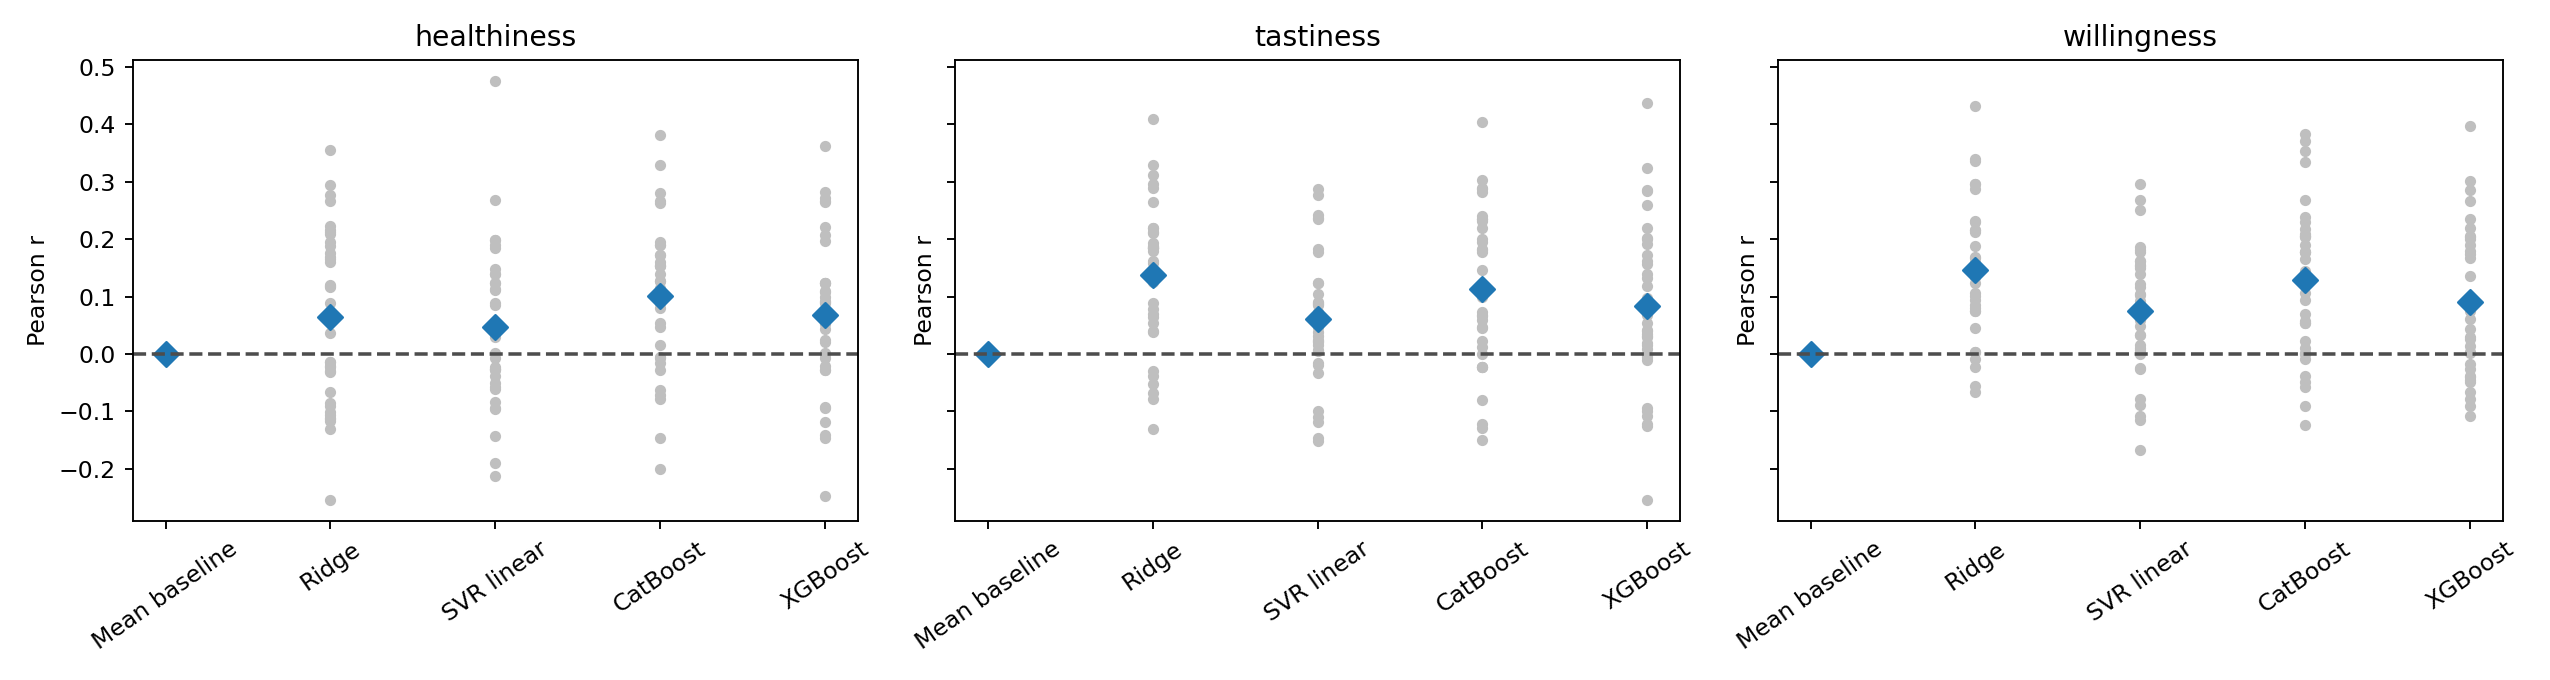

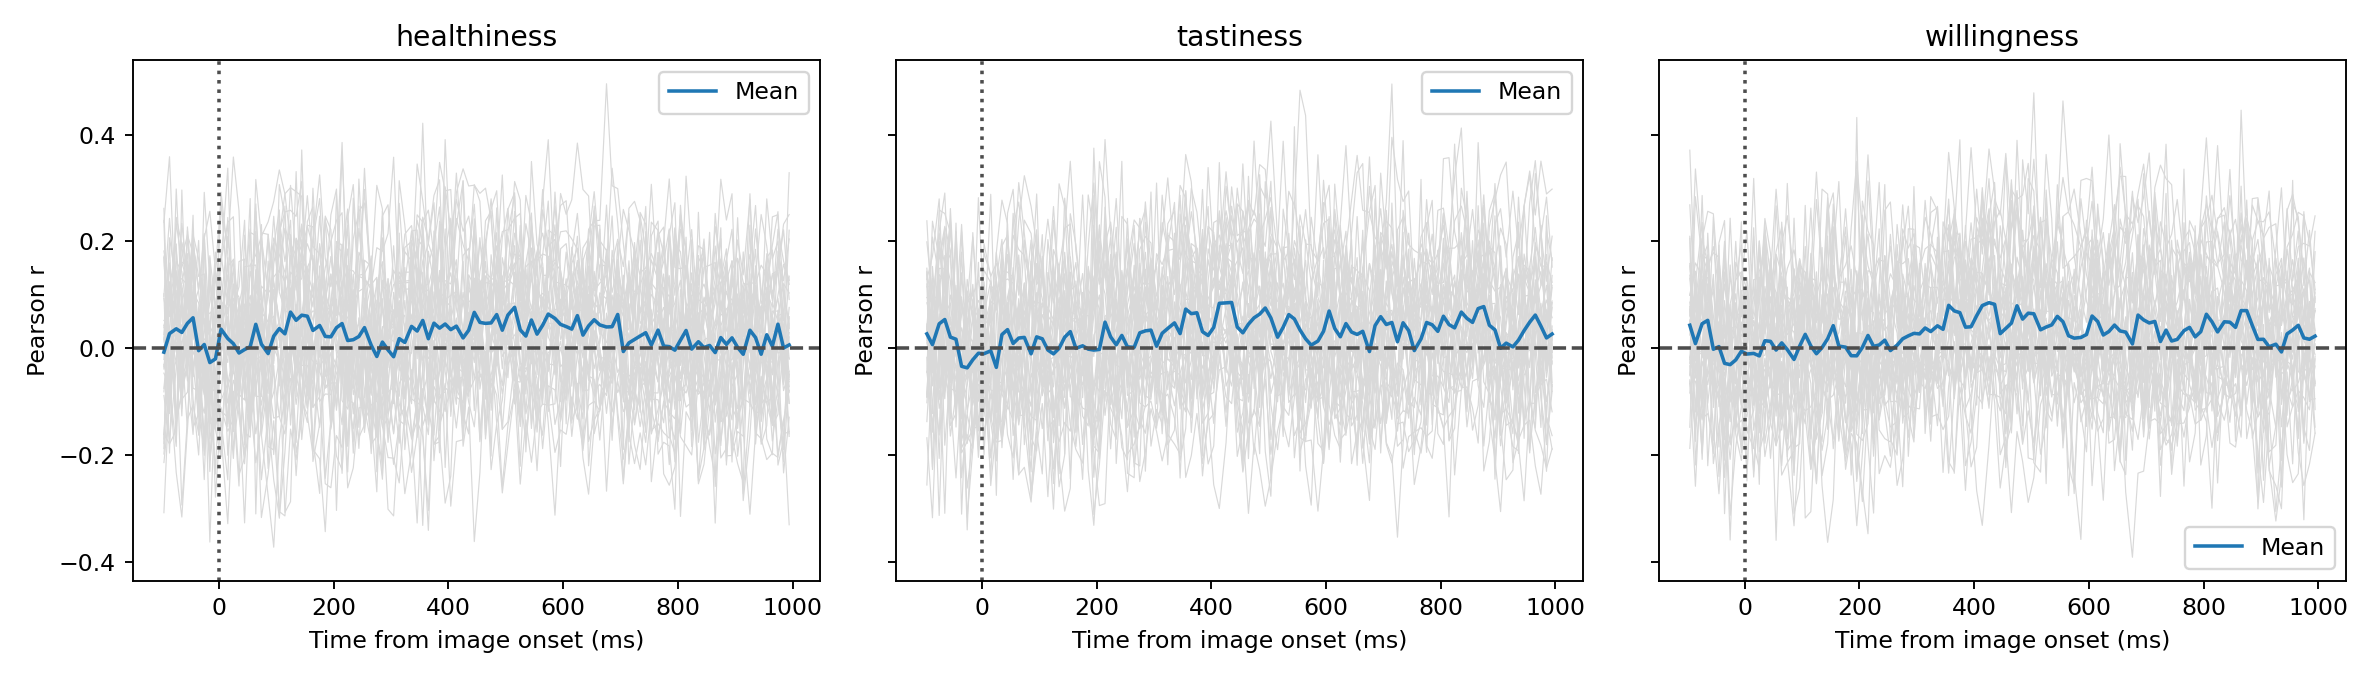

In [4]:
quick_dir = HERE / "results_quick"
if quick_dir.exists():
    display(pd.read_csv(quick_dir / "benchmark_summary.csv").round(4))
    display(Image(filename=str(quick_dir / "benchmark_models.png")))
    display(Image(filename=str(quick_dir / "temporal_svr.png")))
else:
    print("Aucun résultat rapide enregistré dans ce dossier.")


In [ ]:
detail, summary, temporal = run(config, progress=lambda message: print(message, flush=True))
display(summary.round(4))


In [ ]:
clusters, figure = report(temporal, config["output_dir"], n_permutations=5000, seed=42)
display(clusters.round(4))
display(figure)


## Comparaison des modèles sur la fenêtre 200–500 ms
Le modèle baseline prédit toujours la note moyenne du pli d'entraînement.
Une corrélation positive peut coexister avec un R² négatif. Examiner ensemble
r, R² et RMSE avant de parler d'amélioration.


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, target in zip(axes, TARGETS):
    data = detail[detail.target == target]
    for i, model in enumerate(config["models"]):
        values = data[data.model == model].r
        ax.scatter(np.full(len(values), i), values, color="0.75", s=14)
        ax.scatter(i, values.mean(), color="tab:blue", marker="D", s=55)
    ax.axhline(0, color="0.3", linestyle="--")
    ax.set(title=target, ylabel="Pearson r",
           xticks=range(len(config["models"])),
           xticklabels=config["models"])
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(Path(config["output_dir"]) / "benchmark_models.png", dpi=170)
display(fig)


## Fichiers produits
- `benchmark_detail.csv` — subject,target,model,r,R2,RMSE,time_s.
- `benchmark_summary.csv` — target,model,mean_r,std_r,n_r_above_0,mean_R2,mean_RMSE.
- `temporal_detail.csv` — scores par sujet, attribut et fenêtre.
- `temporal_clusters.csv` et figures.
- `protocol.json` et caches par sujet pour reprendre un calcul interrompu.

Les CSV sont affichés avec quatre décimales. Les caches gardent la précision
complète et contiennent des résultats, pas des modèles prédictifs déployables.
Le calcul réalise les entraînements hors test nécessaires à la MVPA.

Les anciens résultats avec z-score par électrode restent une référence
historique ; ils ne doivent pas être présentés comme obtenus avec ce protocole.
